In [6]:
import pandas as pd
import os

In [7]:
here = os.getcwd()
data = pd.read_csv(os.path.join(here,"data.csv"), sep=";", decimal=',')

In [8]:
data["Curricular units 1st sem (grade)"] = pd.to_numeric(data["Curricular units 1st sem (grade)"], errors="coerce")
data["Curricular units 2nd sem (grade)"] = pd.to_numeric(data["Curricular units 2nd sem (grade)"], errors="coerce")

In [9]:
data = data[(data["Curricular units 1st sem (grade)"] <= 20)]
data = data[(data["Curricular units 2nd sem (grade)"] <= 20)]

In [10]:
data.to_csv(os.path.join(here,"semoutliers.csv"), sep=";", index=False)

In [11]:
df = pd.read_csv("semoutliers.csv", sep=";")
df.columns = df.columns.str.strip()

In [12]:
df = df.drop(columns=["Nacionality", "Educational special needs", "International"])

In [13]:
colunas = df.columns.tolist()

In [14]:
cenarioA = df[colunas[0:18] + colunas[30:34]]
cenarioB = df[colunas[0:24] + colunas[30:34]]
cenarioC = df[colunas[0:34]]

cenarioA.to_csv("cenarioA.csv", sep=";", index=False)
cenarioB.to_csv("cenarioB.csv", sep=";", index=False)
cenarioC.to_csv("cenarioC.csv", sep=";", index=False)

print("Ficheiros criados com sucesso:")
print("Cenário A:", cenarioA.shape)
print("Cenário B:", cenarioB.shape)
print("Cenário C:", cenarioC.shape)

Ficheiros criados com sucesso:
Cenário A: (4208, 22)
Cenário B: (4208, 28)
Cenário C: (4208, 34)


In [15]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder


In [16]:
def aplicar_onehot(df, coluna):
    encoder = OneHotEncoder(sparse_output=False)
    codificado = encoder.fit_transform(df[[coluna]])
    nomes = encoder.get_feature_names_out([coluna])
    
    codificado_df = pd.DataFrame(
        codificado,
        columns=nomes,
        index=df.index
    )
    
    df = pd.concat([df.drop(columns=[coluna]), codificado_df], axis=1)
    return df

def processar_cenario(arquivo_entrada, arquivo_saida):
    df = pd.read_csv(arquivo_entrada, sep=";")
    df.columns = df.columns.str.strip()

    df["Marital status"] = df["Marital status"].apply(
        lambda x: "single" if x == 1
        else "married" if x == 2
        else "Other"
    )
    df = aplicar_onehot(df, "Marital status")

    df["Application mode"] = df["Application mode"].apply(
        lambda x: "1st phase - general contingent" if x == 1
        else "2nd phase - general contingent" if x == 17
        else "Over 23 years old" if x == 39
        else "Change of course" if x == 43
        else "Technological specialization diploma holders" if x == 44
        else "Holders of other higher courses" if x == 7
        else "3rd phase - general contingent" if x == 18
        else "Transfer" if x == 42
        else "Change of institution/course" if x == 51
        else "Other"
    )
    df = aplicar_onehot(df, "Application mode")

    df = aplicar_onehot(df, "Course")
    df = aplicar_onehot(df, "Daytime/evening attendance")

    df["Mother's occupation"] = df["Mother's occupation"].apply(
        lambda x: "Unskilled Workers" if x == 9
        else "Administrative staff" if x == 4
        else "Personal Services, Security and Safety Workers and Sellers" if x == 5
        else "Intermediate Level Technicians and Professions" if x == 3
        else "Specialists in Intellectual and Scientific Activities" if x == 2
        else "Skilled Workers in Industry, Construction and Craftsmen" if x == 7
        else "Student" if x == 0
        else "Representatives of the Legislative Power and Executive Bodies, Directors, Directors and Executive Managers" if x == 1
        else "Farmers and Skilled Workers in Agriculture, Fisheries and Forestry" if x == 6
        else "Other Situation" if x == 90
        else "Installation and Machine Operators and Assembly Workers" if x == 8
        else "Other"
    )
    df = aplicar_onehot(df, "Mother's occupation")

    df["Father's occupation"] = df["Father's occupation"].apply(
        lambda x: "Unskilled Workers" if x == 9
        else "Skilled Workers in Industry, Construction and Craftsmen" if x == 7
        else "Personal Services, Security and Safety Workers and Sellers" if x == 5
        else "Administrative staff" if x == 4
        else "Intermediate Level Technicians and Professions" if x == 3
        else "Installation and Machine Operators and Assembly Workers" if x == 8
        else "Armed Forces Professions" if x == 10
        else "Farmers and Skilled Workers in Agriculture, Fisheries and Forestry" if x == 6
        else "Specialists in Intellectual and Scientific Activities" if x == 2
        else "Representatives of the Legislative Power and Executive Bodies, Directors, Directors and Executive Managers" if x == 1
        else "Student" if x == 0
        else "Other Situation" if x == 90
        else "Other"
    )
    df = aplicar_onehot(df, "Father's occupation")

    colunas_diretas = ["Displaced", "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder"]
    for col in colunas_diretas:
        df = aplicar_onehot(df, col)

    df.to_csv(arquivo_saida, sep=";", index=False)
    print(f"Processado: {arquivo_entrada} -> {arquivo_saida}")

cenarios = ["cenarioA", "cenarioB", "cenarioC"]

for cenario in cenarios:
    arquivo_in = f"{cenario}.csv"
    arquivo_out = f"{cenario}_nominais.csv"
    processar_cenario(arquivo_in, arquivo_out)

Processado: cenarioA.csv -> cenarioA_nominais.csv
Processado: cenarioB.csv -> cenarioB_nominais.csv
Processado: cenarioC.csv -> cenarioC_nominais.csv


In [17]:
def aplicar_ordinal(df, coluna, ordem):
    encoder = OrdinalEncoder(categories=[ordem])
    df[coluna] = encoder.fit_transform(
        df[[coluna]]
    ).astype(int).ravel()
    return df

def processar_cenario_ordinal(arquivo_entrada, arquivo_saida):
    df = pd.read_csv(arquivo_entrada, sep=";")
    df.columns = df.columns.str.strip()

    df["Previous qualification"] = df["Previous qualification"].replace({
        3: 40,
        4: 43
    })
    df["Previous qualification"] = df["Previous qualification"].astype(str)
    ordem_previous = [
        "38", "19", "15", "14", "10", "12", "9", "1", "6", "39", "42", "2", "40", "43", "5"
    ]
    df = aplicar_ordinal(df, "Previous qualification", ordem_previous)

    col_mae = "Mother's qualification" if "Mother's qualification" in df.columns else "Mother qualification"
    df[f"{col_mae} is unknown"] = (df[col_mae] == 34).astype(int)
    agrupamento_mae = {
        35: "0", 36: "0", 37: "0",
        18: "1", 19: "1", 26: "1", 27: "1", 29: "1", 30: "1", 38: "1",
        1: "2", 9: "2", 10: "2", 11: "2", 12: "2", 14: "2", 22: "2",
        2: "3", 6: "3", 39: "3", 42: "3",
        3: "4", 4: "4", 5: "4", 40: "4", 41: "4", 43: "4", 44: "4"
    }
    df[col_mae] = df[col_mae].map(agrupamento_mae)
    moda_mae = df[col_mae].dropna().mode()[0]
    df[col_mae] = df[col_mae].fillna(moda_mae)
    ordem_mae = ["0", "1", "2", "3", "4"]
    df = aplicar_ordinal(df, col_mae, ordem_mae)

    col_pai = "Father's qualification" if "Father's qualification" in df.columns else "Father qualification"
    df[f"{col_pai} is unknown"] = (df[col_pai] == 34).astype(int)
    agrupamento_pai = {
        35: "0", 36: "0", 37: "0",
        18: "1", 19: "1", 26: "1", 27: "1", 29: "1", 30: "1", 31: "1", 38: "1",
        1: "2", 9: "2", 10: "2", 11: "2", 12: "2", 13: "2", 14: "2", 20: "2", 22: "2", 25: "2", 33: "2",
        2: "3", 6: "3", 39: "3", 42: "3",
        3: "4", 4: "4", 5: "4", 40: "4", 41: "4", 43: "4", 44: "4"
    }
    df[col_pai] = df[col_pai].map(agrupamento_pai)
    moda_pai = df[col_pai].dropna().mode()[0]
    df[col_pai] = df[col_pai].fillna(moda_pai)
    ordem_pai = ["0", "1", "2", "3", "4"]
    df = aplicar_ordinal(df, col_pai, ordem_pai)

    df.to_csv(arquivo_saida, sep=";", index=False)
    print(f"Processado: {arquivo_entrada} -> {arquivo_saida}")

cenarios = ["cenarioA", "cenarioB", "cenarioC"]

for cenario in cenarios:
    arquivo_in = f"{cenario}_nominais.csv"
    arquivo_out = f"{cenario}_nominais_ordinais.csv"
    processar_cenario_ordinal(arquivo_in, arquivo_out)

Processado: cenarioA_nominais.csv -> cenarioA_nominais_ordinais.csv
Processado: cenarioB_nominais.csv -> cenarioB_nominais_ordinais.csv
Processado: cenarioC_nominais.csv -> cenarioC_nominais_ordinais.csv


In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

SEMENTE = 42
np.random.seed(SEMENTE)

CENARIO = "cenarioC"   
CLASSES = ["Dropout", "Enrolled", "Graduate"]

dados = pd.read_csv(f"{CENARIO}_nominais_ordinais.csv", sep=";", float_precision="round_trip")

y = dados["Target"].map({"Dropout": 0, "Enrolled": 1, "Graduate": 2}).astype(int)
X = dados.drop(columns="Target").astype(float)

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, random_state=SEMENTE, stratify=y
)
X_treino, X_teste = X_treino.to_numpy(), X_teste.to_numpy()
y_treino, y_teste = y_treino.to_numpy(), y_teste.to_numpy()

X_1000 = X_teste[:1000]

print(f"{CENARIO}: {X.shape[0]} linhas e {X.shape[1]} atributos | "
      f"treino = {len(X_treino)} | teste = {len(X_teste)}")

cenarioC: 4208 linhas e 91 atributos | treino = 2945 | teste = 1263


In [15]:
def matriz_confusao(y_real, y_pred, n_classes=3):
    M = np.zeros((n_classes, n_classes), dtype=int)
    for real, pred in zip(y_real, y_pred):
        M[real, pred] += 1
    return M


def relatorio_metricas(M):
    acuracia = np.trace(M) / M.sum()

    precisao, revocacao, f1 = [], [], []
    VP_lista, FP_lista, FN_lista = [], [], []
    for c in range(M.shape[0]):
        VP = M[c, c]
        FP = M[:, c].sum() - VP
        FN = M[c, :].sum() - VP

        P = VP / (VP + FP) if (VP + FP) > 0 else 0.0
        R = VP / (VP + FN) if (VP + FN) > 0 else 0.0
        F = 2 * P * R / (P + R) if (P + R) > 0 else 0.0

        VP_lista.append(VP); FP_lista.append(FP); FN_lista.append(FN)
        precisao.append(P); revocacao.append(R); f1.append(F)

    return {
        "VP": np.array(VP_lista), "FP": np.array(FP_lista), "FN": np.array(FN_lista),
        "precisao": np.array(precisao), "revocacao": np.array(revocacao), "f1": np.array(f1),
        "acuracia": acuracia,
        "f1_macro": float(np.mean(f1)),
        "acuracia_balanceada": float(np.mean(revocacao)),
    }


def tabela_por_classe(m):
    return pd.DataFrame({
        "Classe": CLASSES, "VP": m["VP"], "FP": m["FP"], "FN": m["FN"],
        "Precisão": m["precisao"], "Revocação": m["revocacao"], "F1": m["f1"],
    })


def f1_macro(y_real, y_pred):
    return f1_score(y_real, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)

In [ ]:
def distancia(A, q, metrica):
    dif = A - q
    if metrica == "euclidiana":
        return np.sqrt(np.sum(dif ** 2, axis=1))
    if metrica == "manhattan":
        return np.sum(np.abs(dif), axis=1)
    raise ValueError(f"Métrica desconhecida: {metrica}")


class KNN:
    def __init__(self, k=5, metrica="manhattan"):
        self.K = k
        self.metrica = metrica

    def fit(self, X, y):
        self.X_treino = np.asarray(X, dtype=float)
        self.y_treino = np.asarray(y, dtype=int)
        self.n_classes = int(self.y_treino.max()) + 1
        return self

    def predict_varios_k(self, X, ks):
        k_max = max(ks)
        previsoes = {k: [] for k in ks}
        for q in np.asarray(X, dtype=float):
            d = distancia(self.X_treino, q, self.metrica)
            classes_vizinhos = self.y_treino[np.argsort(d)[:k_max]]
            for k in ks:
                votos = np.bincount(classes_vizinhos[:k], minlength=self.n_classes)
                previsoes[k].append(np.argmax(votos))
        return {k: np.array(v) for k, v in previsoes.items()}

    def predict(self, X):
        return self.predict_varios_k(X, [self.K])[self.K]

In [ ]:
def entropia_contagens(cont):
    cont = np.asarray(cont, dtype=float)
    total = cont.sum(axis=-1, keepdims=True)
    p = cont / np.where(total == 0, 1, total)
    log_p = np.log2(p, out=np.zeros_like(p), where=p > 0)   
    return -(p * log_p).sum(axis=-1)


def gini_contagens(cont):
    cont = np.asarray(cont, dtype=float)
    total = cont.sum(axis=-1, keepdims=True)
    p = cont / np.where(total == 0, 1, total)
    return 1.0 - (p ** 2).sum(axis=-1)


class No:
    def __init__(self, atributo=None, limiar=None, esquerda=None, direita=None, classe=None):
        self.atributo = atributo    
        self.limiar = limiar        
        self.esquerda = esquerda
        self.direita = direita
        self.classe = classe        


class ArvoreDecisao:
    def __init__(self, criterio="gini", max_depth=5, min_samples_leaf=5):
        self.criterio = criterio
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.impureza = gini_contagens if criterio == "gini" else entropia_contagens

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self.n_classes = int(y.max()) + 1
        self.raiz = self._construir(X, y, profundidade=0)
        return self

    def _construir(self, X, y, profundidade):
        contagem = np.bincount(y, minlength=self.n_classes)
        classe_majoritaria = int(np.argmax(contagem))

        if (profundidade >= self.max_depth
                or len(y) < 2 * self.min_samples_leaf
                or contagem.max() == len(y)):         
            return No(classe=classe_majoritaria)

        j, limiar = self._melhor_divisao(X, y)
        if j is None:                                   
            return No(classe=classe_majoritaria)

        esq = X[:, j] <= limiar
        return No(atributo=j, limiar=limiar,
                  esquerda=self._construir(X[esq], y[esq], profundidade + 1),
                  direita=self._construir(X[~esq], y[~esq], profundidade + 1))

    def _melhor_divisao(self, X, y):
        n, d = X.shape
        Y1 = np.eye(self.n_classes)[y]                  
        total = Y1.sum(axis=0)
        imp_pai = self.impureza(total)

        melhor_ganho, melhor_j, melhor_limiar = 0.0, None, None
        n_esq = np.arange(1, n)                         
        n_dir = n - n_esq

        for j in range(d):
            ordem = np.argsort(X[:, j])
            x_ord = X[ordem, j]

            cont_esq = np.cumsum(Y1[ordem], axis=0)[:-1]
            cont_dir = total - cont_esq

            valido = ((x_ord[:-1] != x_ord[1:])
                      & (n_esq >= self.min_samples_leaf)
                      & (n_dir >= self.min_samples_leaf))
            if not valido.any():
                continue

            imp_esq = self.impureza(cont_esq[valido])
            imp_dir = self.impureza(cont_dir[valido])
            ganho = imp_pai - (n_esq[valido] * imp_esq + n_dir[valido] * imp_dir) / n

            k = int(np.argmax(ganho))
            if ganho[k] > melhor_ganho:
                i = np.flatnonzero(valido)[k]
                melhor_ganho = ganho[k]
                melhor_j = j
                melhor_limiar = (x_ord[i] + x_ord[i + 1]) / 2   # ponto médio

        return melhor_j, melhor_limiar

    def _prever_um(self, x):
        no = self.raiz
        while no.classe is None:
            no = no.esquerda if x[no.atributo] <= no.limiar else no.direita
        return no.classe

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._prever_um(x) for x in X])

F1-macro médio da CV: 0.6472 ± 0.0251


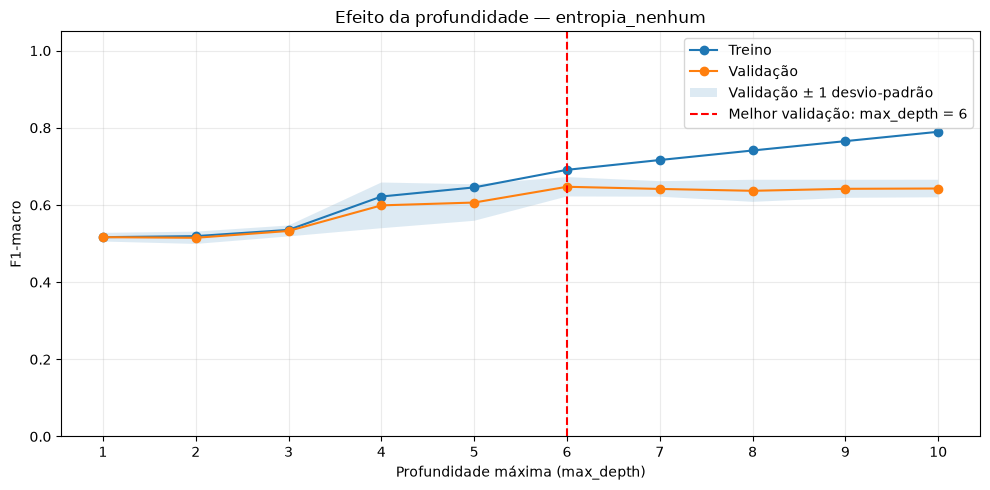


MÉTRICAS DO TESTE — entropia_nenhum (ÁRVORE PRÓPRIA)
max_depth escolhido pela CV: 6
Acurácia: 0.7561
F1-macro: 0.6788
Acurácia balanceada: 0.6724
Concordância com scikit-learn: 100.00%
Tempo mediano de treino: 280.02 ms
Tempo mediano para prever 1000 estudantes: 0.68 ms
Número de atributos após pré-processamento: 91

Métricas por classe:


,Classe,VP,FP,FN,Precisão,Revocação,F1
0,Dropout,307,75,112,0.803665,0.732697,0.766542
1,Enrolled,84,95,141,0.469274,0.373333,0.415842
2,Graduate,564,138,55,0.803419,0.911147,0.853899


In [ ]:

CRITERIO = "entropia"
NOME_ARVORE = "entropia_nenhum"
PROFUNDIDADES = list(range(1, 11))
MIN_SAMPLES_LEAF = 5

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=SEMENTE)
scores_treino = np.zeros((len(PROFUNDIDADES), 5))
scores_val = np.zeros((len(PROFUNDIDADES), 5))

for j, (idx_tr, idx_va) in enumerate(cv.split(X_treino, y_treino)):
    Xtr, Xva = X_treino[idx_tr], X_treino[idx_va]
    ytr, yva = y_treino[idx_tr], y_treino[idx_va]
    for i, prof in enumerate(PROFUNDIDADES):
        arv = ArvoreDecisao(CRITERIO, max_depth=prof, min_samples_leaf=MIN_SAMPLES_LEAF).fit(Xtr, ytr)
        scores_treino[i, j] = f1_macro(ytr, arv.predict(Xtr))
        scores_val[i, j] = f1_macro(yva, arv.predict(Xva))

f1_treino = scores_treino.mean(axis=1)
f1_val = scores_val.mean(axis=1)
desvio_val = scores_val.std(axis=1, ddof=1)

i_melhor = int(np.argmax(f1_val))
melhor_prof = PROFUNDIDADES[i_melhor]
f1_cv_arvore, desvio_cv_arvore = f1_val[i_melhor], desvio_val[i_melhor]

print(f"F1-macro médio da CV: {f1_cv_arvore:.4f} ± {desvio_cv_arvore:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(PROFUNDIDADES, f1_treino, marker="o", label="Treino")
plt.plot(PROFUNDIDADES, f1_val, marker="o", label="Validação")
plt.fill_between(PROFUNDIDADES, f1_val - desvio_val, f1_val + desvio_val, alpha=0.15,
                 label="Validação ± 1 desvio-padrão")
plt.axvline(melhor_prof, color="red", linestyle="--", label=f"Melhor validação: max_depth = {melhor_prof}")
plt.xlabel("Profundidade máxima (max_depth)")
plt.ylabel("F1-macro")
plt.title(f"Efeito da profundidade — {NOME_ARVORE}")
plt.xticks(PROFUNDIDADES)
plt.ylim(0, 1.05)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(f"profundidade_{NOME_ARVORE}.png", dpi=300)
plt.show()

tempos_treino, tempos_pred_1000 = [], []
for _ in range(5):
    arv = ArvoreDecisao(CRITERIO, max_depth=melhor_prof, min_samples_leaf=MIN_SAMPLES_LEAF)
    t0 = time.perf_counter()
    arv.fit(X_treino, y_treino)
    tempos_treino.append((time.perf_counter() - t0) * 1000)

    t0 = time.perf_counter()
    arv.predict(X_1000)
    tempos_pred_1000.append((time.perf_counter() - t0) * 1000)

y_pred_arvore = arv.predict(X_teste)
m_arvore = relatorio_metricas(matriz_confusao(y_teste, y_pred_arvore))

arv_sk = DecisionTreeClassifier(criterion="entropy", max_depth=melhor_prof,
                                min_samples_leaf=MIN_SAMPLES_LEAF, random_state=SEMENTE)
arv_sk.fit(X_treino, y_treino)
concordancia_arvore = np.mean(y_pred_arvore == arv_sk.predict(X_teste)) * 100

print(f"\nMÉTRICAS DO TESTE — {NOME_ARVORE} (ÁRVORE PRÓPRIA)")
print(f"max_depth escolhido pela CV: {melhor_prof}")
print(f"Acurácia: {m_arvore['acuracia']:.4f}")
print(f"F1-macro: {m_arvore['f1_macro']:.4f}")
print(f"Acurácia balanceada: {m_arvore['acuracia_balanceada']:.4f}")
print(f"Concordância com scikit-learn: {concordancia_arvore:.2f}%")
print(f"Tempo mediano de treino: {np.median(tempos_treino):.2f} ms")
print(f"Tempo mediano para prever 1000 estudantes: {np.median(tempos_pred_1000):.2f} ms")
print(f"Número de atributos após pré-processamento: {X_teste.shape[1]}\n")
print("Métricas por classe:")
display(tabela_por_classe(m_arvore))

Melhor k encontrado: 11 (F1-macro CV: 0.6162 Desvio-padrão: 0.0338)


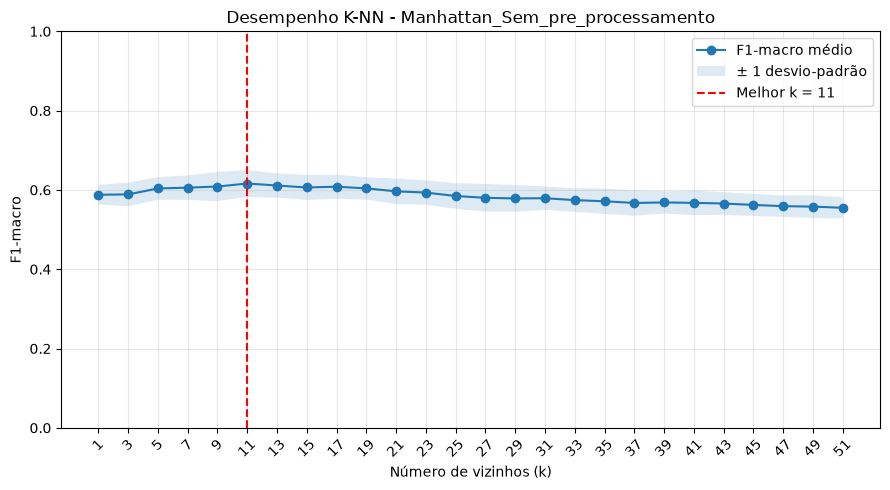


Relatório de Métricas no Teste:
  Classe  VP  FP  FN  Precisão  Revocação       F1
 Dropout 264  62 155  0.809816   0.630072 0.708725
Enrolled  51  74 174  0.408000   0.226667 0.291429
Graduate 578 234  41  0.711823   0.933764 0.807827

Acurácia: 0.7070
F1-macro: 0.6027
Acurácia balanceada: 0.5968

Tempo Treino: 0.14 ms
Tempo Predição (Todos): 361.86 ms
Tempo Predição (1000 amostras): 270.49 ms
Concordância com Scikit-Learn: 100.00%


In [ ]:
METRICA = "manhattan"
NOME_KNN = "Manhattan_Sem_pre_processamento"
KS = list(range(1, 52, 2))                      # k de 1 a 51

cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEMENTE)
scores = {k: [] for k in KS}

for idx_tr, idx_va in cv.split(X_treino, y_treino):
    previsoes = KNN(metrica=METRICA).fit(X_treino[idx_tr], y_treino[idx_tr]).predict_varios_k(X_treino[idx_va], KS)
    for k in KS:
        scores[k].append(f1_macro(y_treino[idx_va], previsoes[k]))

medias_cv = np.array([np.mean(scores[k]) for k in KS])
desvios_cv = np.array([np.std(scores[k], ddof=1) for k in KS])

i_melhor = int(np.argmax(medias_cv))
melhor_k = KS[i_melhor]

print(f"Melhor k encontrado: {melhor_k} (F1-macro CV: {medias_cv[i_melhor]:.4f} "
      f"Desvio-padrão: {desvios_cv[i_melhor]:.4f})")

plt.figure(figsize=(9, 5))
plt.plot(KS, medias_cv, marker="o", label="F1-macro médio")
plt.fill_between(KS, medias_cv - desvios_cv, medias_cv + desvios_cv, alpha=0.15, label="± 1 desvio-padrão")
plt.axvline(melhor_k, color="red", linestyle="--", label=f"Melhor k = {melhor_k}")
plt.xlabel("Número de vizinhos (k)")
plt.ylabel("F1-macro")
plt.title(f"Desempenho K-NN - {NOME_KNN}")
plt.xticks(KS, rotation=45)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"desempenho_{NOME_KNN}.png", dpi=300)
plt.show()

t0 = time.perf_counter()
modelo_knn = KNN(k=melhor_k, metrica=METRICA).fit(X_treino, y_treino)
tempo_treino_knn = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
y_pred_knn = modelo_knn.predict(X_teste)
tempo_pred_knn = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
modelo_knn.predict(X_1000)
tempo_pred_1000_knn = (time.perf_counter() - t0) * 1000

m_knn = relatorio_metricas(matriz_confusao(y_teste, y_pred_knn))

# comparação com o scikitlearn
knn_sk = KNeighborsClassifier(n_neighbors=melhor_k, metric=METRICA).fit(X_treino, y_treino)
concordancia_knn = np.mean(y_pred_knn == knn_sk.predict(X_teste)) * 100

print("\nRelatório de Métricas no Teste:")
print(tabela_por_classe(m_knn).to_string(index=False))
print(f"\nAcurácia: {m_knn['acuracia']:.4f}")
print(f"F1-macro: {m_knn['f1_macro']:.4f}")
print(f"Acurácia balanceada: {m_knn['acuracia_balanceada']:.4f}\n")
print(f"Tempo Treino: {tempo_treino_knn:.2f} ms")
print(f"Tempo Predição (Todos): {tempo_pred_knn:.2f} ms")
print(f"Tempo Predição (1000 amostras): {tempo_pred_1000_knn:.2f} ms")
print(f"Concordância com Scikit-Learn: {concordancia_knn:.2f}%")

In [ ]:
def pct(v):
    return f"{v * 100:.2f}%".replace(".", ",")

def num(v):
    return f"{v:.4f}".replace(".", ",")

print(f"Árvore de Decisão: A melhor configuração utilizou o critério {CRITERIO.capitalize()}, "
      f"sem pré-processamento (sem escalonamento numérico ou PCA) e com profundidade máxima de {melhor_prof}. "
      f"Esse modelo alcançou uma acurácia de {pct(m_arvore['acuracia'])} e um F1-macro de "
      f"{num(m_arvore['f1_macro'])} nos dados de teste.")
print()
print(f"k-NN: A configuração ideal utilizou a métrica de distância {METRICA.capitalize()}, "
      f"sem pré-processamento e com k = {melhor_k} vizinhos. "
      f"Esta abordagem obteve uma acurácia de {pct(m_knn['acuracia'])} e um F1-macro de "
      f"{num(m_knn['f1_macro'])} nos dados de teste.")

Árvore de Decisão: A melhor configuração utilizou o critério Entropia, sem pré-processamento (sem escalonamento numérico ou PCA) e com profundidade máxima de 6. Esse modelo alcançou uma acurácia de 75,61% e um F1-macro de 0,6788 nos dados de teste.

k-NN: A configuração ideal utilizou a métrica de distância Manhattan, sem pré-processamento e com k = 11 vizinhos. Esta abordagem obteve uma acurácia de 70,70% e um F1-macro de 0,6027 nos dados de teste.
